## Cell 1: Getting the building data ready

**Owner: Yera Smagulov. Target: MFBTU, annual major-fuels consumption in kBtu.**

Keep all 23 original inputs. Add missing-value flags, privacy-threshold flags,
and a few useful combinations. Use a fixed 70/15/15 split; no cross-validation
or model-based feature removal. Run cells in order. Results go to `data/processed`.

## Cell 2: Who could use this?

Our user is an acquisition analyst doing due diligence without utility bills.
They have property records and a walkthrough, can ask the seller about operations
and equipment, and can obtain weather for a stated reference year.

That is more information than a basic listing. Hours, staffing, occupancy, and
equipment are not guaranteed to be public. `documentation/feature_availability.csv`
lists a source and a limitation for each input. Missing values stay marked.
For a listing-only tool, the team should separately validate a property-only model.

## Cell 3: Sources

[EIA microdata](https://www.eia.gov/consumption/commercial/data/2018/index.php?view=microdata),
[codebook](https://www.eia.gov/consumption/commercial/data/2018/xls/2018microdata_codebook.xlsx),
and [user guide, printed pp. 17-21](https://www.eia.gov/consumption/commercial/data/2018/pdf/Users%20Guide%20to%20the%202018%20CBECS%20Public%20Use%20Microdata%20File.pdf).

The guide says areas over 1 million square feet are replaced by regional averages;
worker counts of 5,000 or more are replaced by a national average. These are
privacy replacements, not exact measurements of those large buildings.

In [1]:
# Cell 4: Load the data and define all 23 inputs
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
cwd = Path.cwd()
root = next((p for p in [cwd, cwd.parent] if (p / 'data/raw/cbecs2018_final_public.csv').exists()),
            cwd.parent if cwd.name == 'notebooks' else cwd)
output_dir, doc_dir = root / 'data/processed', root / 'documentation'
output_dir.mkdir(parents=True, exist_ok=True)
doc_dir.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(root / 'data/raw/cbecs2018_final_public.csv')
book = pd.read_csv(root / 'data/raw/codebook_snapshot.csv', header=1)
book.columns = ['order', 'variable', 'type', 'description', 'codes', 'question']
numeric = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
categorical = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP',
               'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
source_features = numeric + categorical
assert len(source_features) == 23 and raw.shape == (6436, 1249)
assert raw.PUBID.is_unique and raw.PUBID.notna().all()
display(book.loc[book.variable.isin(source_features), ['variable', 'description']].reset_index(drop=True))


,variable,description
0,CENDIV,Census division
1,PBA,Principal building activity
2,PUBCLIM,Third-party data: ASHRAE climate zone
3,SQFT,Square footage
4,WLCNS,Wall construction material
5,RFCNS,Roof construction material
6,RFTILT,Roof tilt
7,BLDSHP,Building shape
8,GLSSPC,Percent exterior glass
9,NFLOOR,Number of floors


## Cell 5: Keep the fixed validation set

Drop only buildings without an applicable target. Keep occupancy percentage
and every other source input, even when many values are missing. EIA's supplied
imputations stay in place.

We use 4,449 training, 954 validation, and 954 test buildings. Learn preprocessing
from training only, use validation for model and feature-engineering choices,
and leave test performance for the final project evaluation.

In [2]:
# Cell 6: Filter the target and assign the splits
missing_target = raw.MFBTU.isna()
assert raw.loc[missing_target, 'ZMFBTU'].eq(9).all()
data = raw.loc[~missing_target].sort_values('PUBID').copy()
excluded = raw.loc[missing_target, ['PUBID', 'ZMFBTU']].copy()
excluded['reason'] = 'MFBTU not applicable; target not filled'
assert np.isfinite(data.MFBTU).all() and data.MFBTU.ge(0).all()
train_rows, held_out = train_test_split(data.index, test_size=0.30, random_state=SEED)
validation_rows, test_rows = train_test_split(held_out, test_size=0.50, random_state=SEED)
splits = {'train': sorted(train_rows), 'validation': sorted(validation_rows), 'test': sorted(test_rows)}
display(pd.DataFrame({'Buildings': {name: len(rows) for name, rows in splits.items()}}))
display(data.loc[splits['train'], source_features].isna().sum().rename('Missing training values').to_frame())


,Buildings
train,4449
validation,954
test,954


,Missing training values
SQFT,0
FLCEILHT,0
WKHRS,0
NWKER,0
MONUSE,0
HDD65,0
CDD65,0
HEATP,251
COOLP,265
OCCUPYP,3191


## Cell 7: Mark missing values and privacy thresholds

Each original input gets an `__is_missing` flag before filling: 1 means blank.
These include questionnaire skips; a blank is not assumed to be zero. Flags
do not identify values that EIA already filled before publication.

Cap model SQFT at 1,000,000 and NWKER at 5,000. Separate flags mark SQFT > 1,000,000
and NWKER >= 5,000 before capping. Keep the published source values separately.
Floor codes 994/995 stay categories. Ceiling height over 50 uses a bound and flag.

In [3]:
# Cell 8: Clean inputs without learning from held-out rows
def clean_inputs(frame):
    source = frame.reindex(columns=source_features).copy()
    flags = source.isna().astype(float).add_suffix('__is_missing')
    numbers = source[numeric].apply(pd.to_numeric, errors='raise').astype(float)
    flags['SQFT__above_1m'] = numbers.SQFT.gt(1_000_000).astype(float)
    flags['NWKER__5000_or_more'] = numbers.NWKER.ge(5_000).astype(float)
    flags['FLCEILHT__above_50'] = numbers.FLCEILHT.gt(50).astype(float)
    numbers['SQFT'] = numbers.SQFT.clip(upper=1_000_000)
    numbers['NWKER'] = numbers.NWKER.clip(upper=5_000)
    numbers['FLCEILHT'] = numbers.FLCEILHT.clip(upper=50)
    groups = pd.DataFrame(index=source.index)
    for col in categorical:
        groups[col] = source[col].map(lambda v: 'missing' if pd.isna(v) else f'code_{int(v)}')
    groups['NFLOOR'] = groups.NFLOOR.replace({'code_994': '10_to_14', 'code_995': '15_or_more'})
    groups['PUBCLIM'] = groups.PUBCLIM.replace({'code_7': 'withheld'})
    return numbers, groups, flags

numbers, groups, flags = clean_inputs(data)
assert numbers.SQFT.le(1_000_000).all() and numbers.NWKER.le(5_000).all()
display(flags[['SQFT__above_1m', 'NWKER__5000_or_more']].sum().rename('Flagged buildings').to_frame())


,Flagged buildings
SQFT__above_1m,125.0
NWKER__5000_or_more,15.0


## Cell 9: Try a few combinations

All 23 inputs stay. We also try eight combinations: log size and staffing,
workers per 1,000 square feet, area × operating hours, heated/cooled area,
and heated/cooled area × heating/cooling degree days.

These are plausible signals, not guaranteed improvements. They use filled,
capped values, so ratios and exposures for masked or missing inputs are approximate.
Original missing flags remain available to the model.

In [4]:
# Cell 10: Fit fills and build the engineered features
imputer = SimpleImputer(strategy='median').fit(numbers.loc[splits['train']])
filled = pd.DataFrame(imputer.transform(numbers), index=data.index, columns=numeric)

def add_combinations(values):
    result = values.copy()
    area = values.SQFT
    result['log1p_SQFT'] = np.log1p(area)
    result['log1p_NWKER'] = np.log1p(values.NWKER)
    result['workers_per_1000_sqft'] = 1000 * values.NWKER / area
    result['weekly_floor_area_hours'] = area * values.WKHRS
    result['heated_floor_area'] = area * values.HEATP / 100
    result['cooled_floor_area'] = area * values.COOLP / 100
    result['heating_area_degree_days'] = result.heated_floor_area * values.HDD65
    result['cooling_area_degree_days'] = result.cooled_floor_area * values.CDD65
    return result

continuous = add_combinations(filled)
engineered = [c for c in continuous if c not in numeric]
assert len(engineered) == 8
print('Engineered:', ', '.join(engineered))
display(pd.Series(dict(zip(numeric, imputer.statistics_)), name='Training median').to_frame())


Engineered: log1p_SQFT, log1p_NWKER, workers_per_1000_sqft, weekly_floor_area_hours, heated_floor_area, cooled_floor_area, heating_area_degree_days, cooling_area_degree_days


,Training median
SQFT,75000.0
FLCEILHT,11.0
WKHRS,60.0
NWKER,40.0
MONUSE,12.0
HDD65,4502.0
CDD65,1461.0
HEATP,100.0
COOLP,100.0
OCCUPYP,96.0


## Cell 11: Encode and scale for the models

Fit categories and scaling on training only. Missing and threshold flags stay
0/1. Boosting gets unscaled values; the neural network and linear regression
get standardized continuous values. The target stays in kBtu.

We also export a base version without the eight combinations for a fair
feature-engineering comparison. Both versions retain every original variable.

In [5]:
# Cell 12: Create the base and engineered matrices
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=float)
encoder.fit(groups.loc[splits['train']])
category_names = [f'{c}__{level}' for c, levels in zip(categorical, encoder.categories_) for level in levels]
scaler = StandardScaler().fit(continuous.loc[splits['train']])

def make_features(rows, scale=False, include_engineered=True):
    values = continuous.loc[rows].copy()
    if scale:
        values = pd.DataFrame(scaler.transform(values), index=rows, columns=continuous.columns)
    if not include_engineered:
        values = values[numeric]
    encoded = pd.DataFrame(encoder.transform(groups.loc[rows]), index=rows, columns=category_names)
    return pd.concat([values, flags.loc[rows], encoded], axis=1)

X_tree = {name: make_features(rows) for name, rows in splits.items()}
X_scaled = {name: make_features(rows, scale=True) for name, rows in splits.items()}
X_base = {name: make_features(rows, include_engineered=False) for name, rows in splits.items()}
X_base_scaled = {name: make_features(rows, scale=True, include_engineered=False) for name, rows in splits.items()}
y = {name: data.loc[rows, ['MFBTU']].copy() for name, rows in splits.items()}
display(pd.DataFrame({name: {'Buildings': len(rows), 'Base columns': X_base[name].shape[1],
    'With combinations': X_tree[name].shape[1]} for name, rows in splits.items()}).T)


,Buildings,Base columns,With combinations
train,4449,175,183
validation,954,175,183
test,954,175,183


## Cell 13: A quick look at training data

Energy use has a long right tail. Bigger buildings generally use more, but
there is plenty of variation. Building types also differ in size and schedules.
These unweighted plots show associations, not cause and effect. The size plot
shows the capped model input and marks the large-building group.

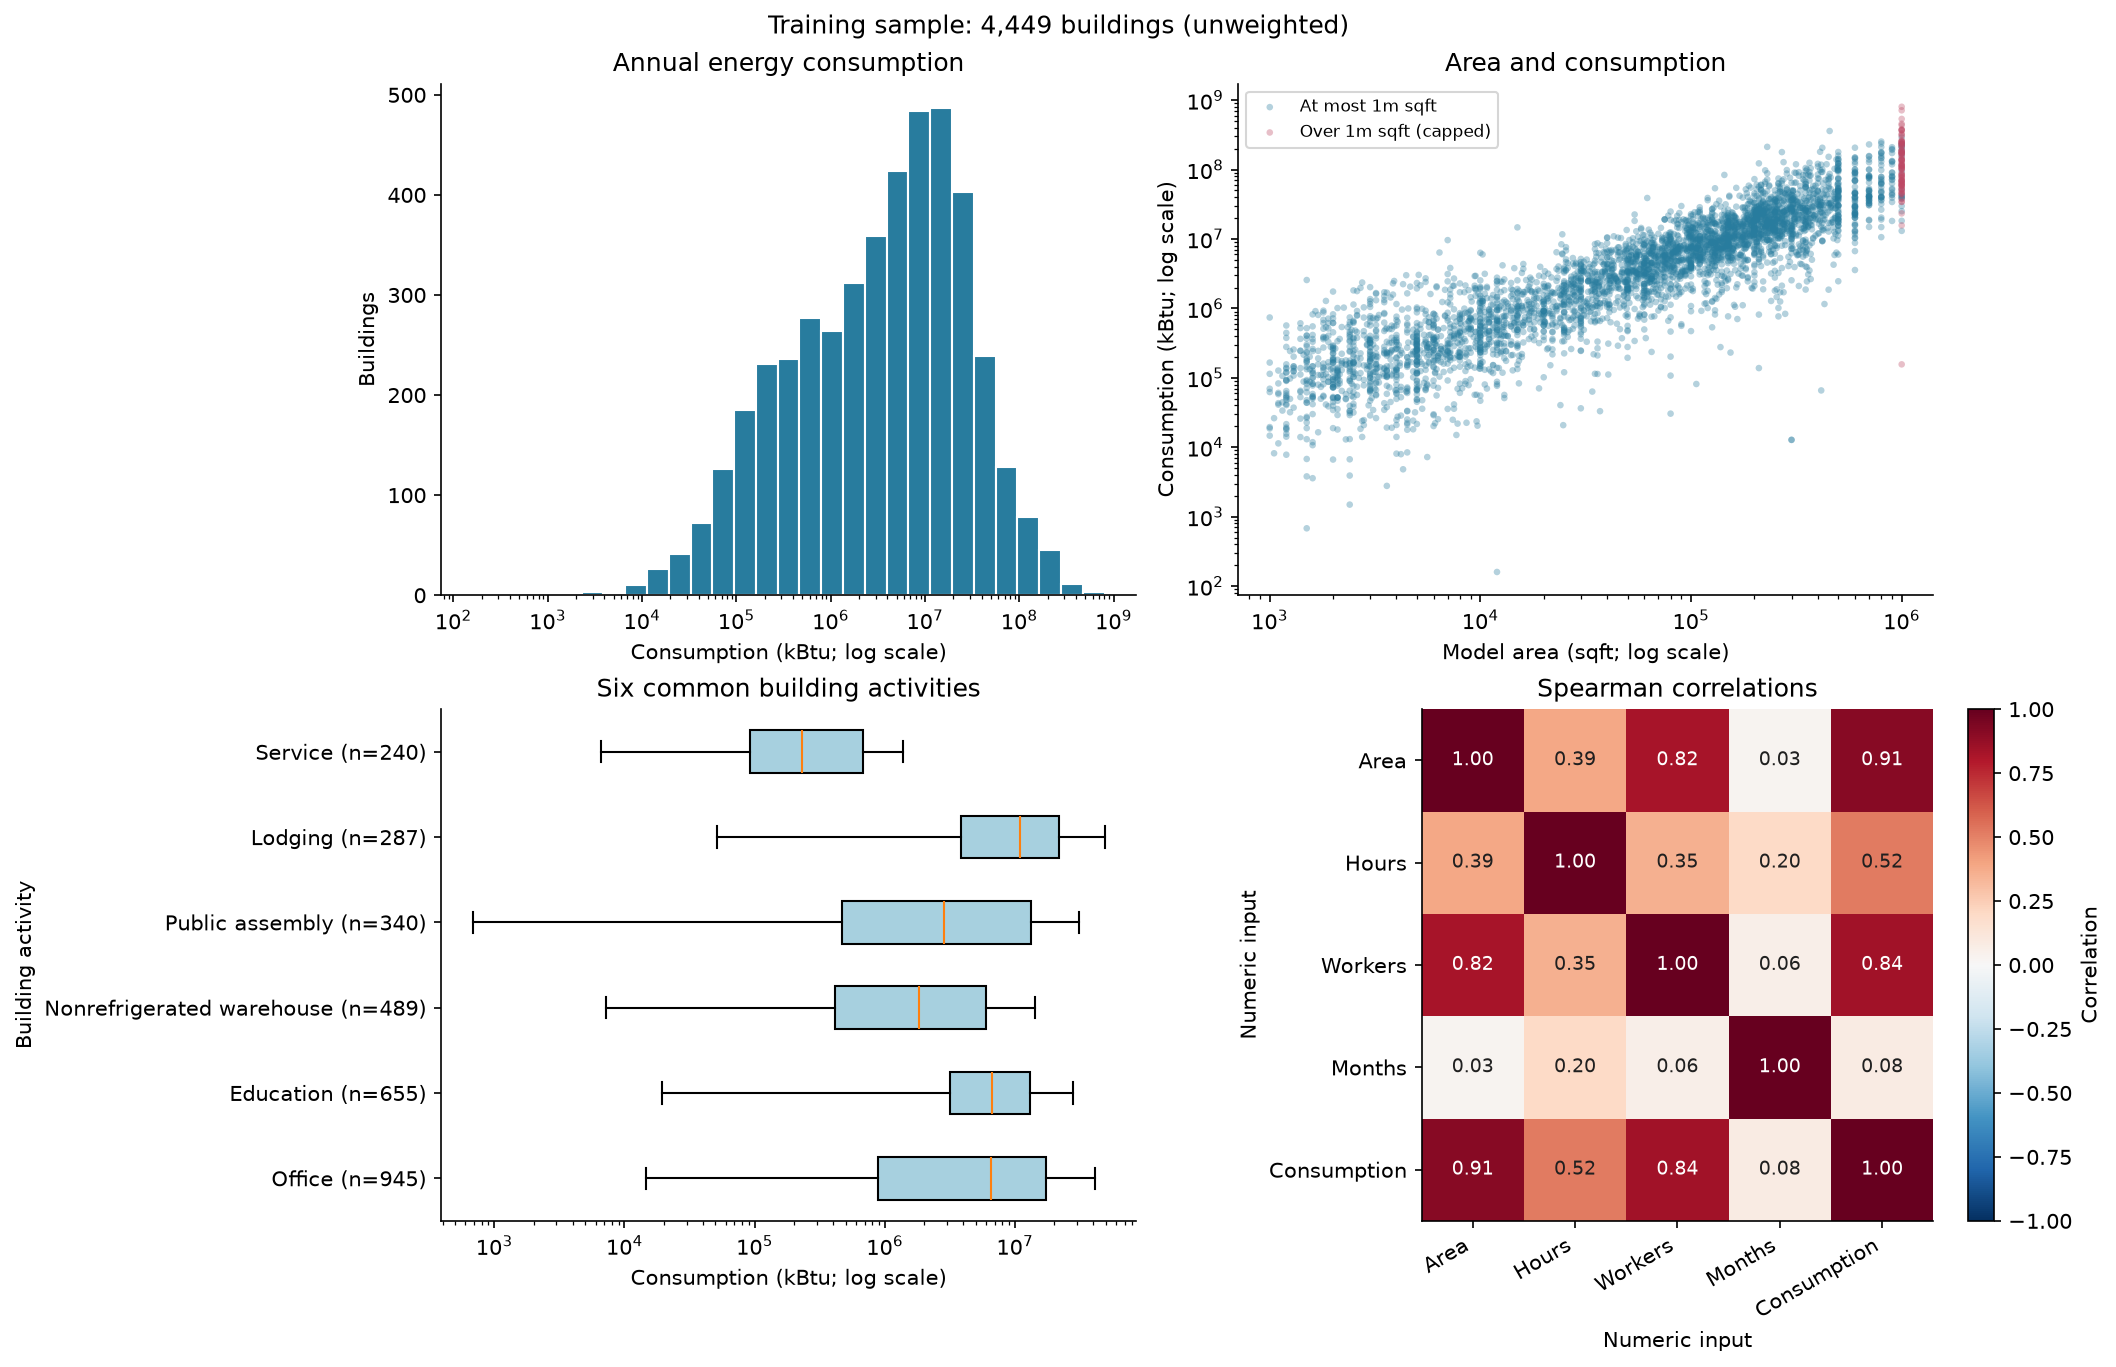

Consumption median: 4,397,988; mean: 15,868,331 kBtu.
Box plots hide outlier points only; all eligible buildings are retained.


In [6]:
# Cell 14: Draw a short EDA overview
import matplotlib.pyplot as plt
from IPython.display import Image

figure_dir = root / 'figures/eda'
figure_dir.mkdir(parents=True, exist_ok=True)
train = data.loc[splits['train']]
energy = train.MFBTU
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
axes[0, 0].hist(energy, bins=np.geomspace(energy.min(), energy.max(), 30), color='#287c9e', edgecolor='white')
axes[0, 0].set(xscale='log', title='Annual energy consumption', xlabel='Consumption (kBtu; log scale)', ylabel='Buildings')
for marked, label, color in [(False, 'At most 1m sqft', '#287c9e'), (True, 'Over 1m sqft (capped)', '#bd4864')]:
    idx = train.index[flags.loc[train.index, 'SQFT__above_1m'].eq(float(marked))]
    axes[0, 1].scatter(numbers.loc[idx, 'SQFT'], data.loc[idx, 'MFBTU'], s=10, alpha=0.35, color=color, edgecolors='none', label=label)
axes[0, 1].set(xscale='log', yscale='log', title='Area and consumption', xlabel='Model area (sqft; log scale)', ylabel='Consumption (kBtu; log scale)')
axes[0, 1].legend(fontsize=8)
mapping = str(book.loc[book.variable.eq('PBA'), 'codes'].iloc[0])
pba_names = {int(line.split('=', 1)[0]): line.split('=', 1)[1].strip() for line in mapping.splitlines() if '=' in line}
common = train.PBA.value_counts().head(6)
boxes = axes[1, 0].boxplot([train.loc[train.PBA.eq(c), 'MFBTU'].to_numpy() for c in common.index],
    orientation='horizontal', tick_labels=[f'{pba_names[c]} (n={n})' for c, n in common.items()], showfliers=False, patch_artist=True)
for box in boxes['boxes']:
    box.set_facecolor('#a7d0df')
axes[1, 0].set(xscale='log', title='Six common building activities', xlabel='Consumption (kBtu; log scale)', ylabel='Building activity')
correlation_data = numbers.loc[train.index, ['SQFT', 'WKHRS', 'NWKER', 'MONUSE']].join(train[['MFBTU']])
correlations = correlation_data.corr(method='spearman')
labels = ['Area', 'Hours', 'Workers', 'Months', 'Consumption']
heatmap = axes[1, 1].imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
axes[1, 1].set_xticks(range(5), labels, rotation=30, ha='right')
axes[1, 1].set_yticks(range(5), labels)
axes[1, 1].set(title='Spearman correlations', xlabel='Numeric input', ylabel='Numeric input')
for i in range(5):
    for j in range(5):
        value = correlations.iloc[i, j]
        axes[1, 1].text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if abs(value) > .65 else '#202020', fontsize=9)
fig.colorbar(heatmap, ax=axes[1, 1], label='Correlation')
fig.suptitle(f'Training sample: {len(train):,} buildings (unweighted)')
plot_path = figure_dir / 'eda_overview.png'
fig.savefig(plot_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(plot_path)))
correlations.to_csv(figure_dir / 'training_correlations.csv')
print(f'Consumption median: {energy.median():,.0f}; mean: {energy.mean():,.0f} kBtu.')
print('Box plots hide outlier points only; all eligible buildings are retained.')


## Cell 15: Does feature engineering help on validation?

Compare the base and engineered inputs on the same 954 validation buildings.
Use two quick, fixed-setting models as a check, not a final model competition.
Their fitting target is log1p(MFBTU); scores are converted back to kBtu.
The neural-network experiment can use the same files. Do not score the test set yet.

In [7]:
# Cell 16: Run one fixed validation comparison
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

validation_results = []
for variant in ['base', 'engineered']:
    scaled_frames = X_base_scaled if variant == 'base' else X_scaled
    tree_frames = X_base if variant == 'base' else X_tree
    for model_name in ['Ridge check', 'Gradient boosting check']:
        if model_name == 'Ridge check':
            model, frames = Ridge(alpha=10), scaled_frames
        else:
            model = HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15,
                min_samples_leaf=20, l2_regularization=1, random_state=SEED)
            frames = tree_frames
        model.fit(frames['train'], np.log1p(y['train'].MFBTU))
        predictions = np.expm1(model.predict(frames['validation']))
        actual = y['validation'].MFBTU
        assert np.isfinite(predictions).all()
        validation_results.append({'model': model_name, 'inputs': variant,
            'MAE_kBtu': mean_absolute_error(actual, predictions),
            'RMSE_kBtu': np.sqrt(mean_squared_error(actual, predictions)), 'R2': r2_score(actual, predictions)})
validation_results = pd.DataFrame(validation_results)
display(validation_results.round(3))
validation_results.to_csv(doc_dir / 'feature_engineering_validation.csv', index=False)


,model,inputs,MAE_kBtu,RMSE_kBtu,R2
0,Ridge check,base,1.204799e+07,6.642627e+07,-2.316
1,Gradient boosting check,base,4.776923e+06,1.637148e+07,0.799
2,Ridge check,engineered,4.389292e+06,1.479438e+07,0.836
3,Gradient boosting check,engineered,4.519645e+06,1.551938e+07,0.819


## Cell 17: Check the edge cases

Check the exact cap boundaries, missing flags, split membership, and unchanged
targets. Missing flags are made before filling. Numeric features and targets
must be finite in model files. No observations are dropped for outliers.

In [8]:
# Cell 18: Validate flags, boundaries, and model inputs
probe = data[source_features].iloc[:4].copy()
probe['SQFT'] = [1_000_000, 1_000_001, np.nan, 2_000_000]
probe['NWKER'] = [4999, 5000, 7500, np.nan]
probe_numbers, _, probe_flags = clean_inputs(probe)
assert probe_flags['SQFT__above_1m'].tolist() == [0, 1, 0, 1]
assert probe_flags['NWKER__5000_or_more'].tolist() == [0, 1, 1, 0]
assert probe_flags['SQFT__is_missing'].tolist() == [0, 0, 1, 0]
assert probe_flags['NWKER__is_missing'].tolist() == [0, 0, 0, 1]
assert probe_numbers.SQFT.dropna().le(1_000_000).all()
assert probe_numbers.NWKER.dropna().le(5_000).all()
assert flags[[c + '__is_missing' for c in source_features]].to_numpy().astype(bool).tolist() == data[source_features].isna().to_numpy().tolist()
assert len(source_features) == 23 and 'OCCUPYP' in X_tree['train']
assert set(numeric).issubset(X_tree['train'].columns)
all_rows = [i for rows in splits.values() for i in rows]
assert len(all_rows) == len(set(all_rows)) == len(data)
feature_order = X_tree['train'].columns.tolist()
assert not {'PUBID', 'MFBTU', 'FINALWT', 'ZMFBTU'}.intersection(feature_order)
for name, rows in splits.items():
    assert X_tree[name].columns.tolist() == X_scaled[name].columns.tolist() == feature_order
    assert np.isfinite(X_tree[name].to_numpy()).all() and np.isfinite(X_scaled[name].to_numpy()).all()
    assert np.array_equal(y[name].MFBTU.to_numpy(), raw.loc[rows, 'MFBTU'].to_numpy())
assert np.allclose(X_scaled['train'][continuous.columns].mean(), 0, atol=1e-10)
assert np.allclose(X_scaled['train'][continuous.columns].std(ddof=0), 1, atol=1e-10)
assert np.allclose(imputer.statistics_, numbers.loc[splits['train']].median())
assert np.array_equal(X_scaled['train'][flags.columns].to_numpy(), flags.loc[splits['train']].to_numpy())
assert np.allclose(continuous.workers_per_1000_sqft, 1000 * filled.NWKER / filled.SQFT)
print('Passed: all 23 inputs, 23 missing flags, threshold boundaries, row alignment, scaling, and original targets.')


Passed: all 23 inputs, 23 missing flags, threshold boundaries, row alignment, scaling, and original targets.


## Cell 19: Save files for the team

`X_<split>_tree` and `X_<split>_scaled` include the eight combinations.
`X_<split>_base` and `X_<split>_base_scaled` leave only the combinations out.
Both retain all 23 source variables, missing flags, and threshold handling.
The matching y and metadata files have the same row order. In the combined
CSV, exclude PUBID, split, and MFBTU from X.

In [9]:
# Cell 20: Export the dataset and preprocessing settings
membership = data[['PUBID']].copy()
membership['split'] = ''
metadata_columns = ['PUBID', 'FINALWT', 'ZMFBTU'] + ['Z' + c for c in source_features if 'Z' + c in data]
for name, rows in splits.items():
    membership.loc[rows, 'split'] = name
    for label, frames in [('tree', X_tree), ('scaled', X_scaled), ('base', X_base), ('base_scaled', X_base_scaled)]:
        frames[name].to_csv(output_dir / f'X_{name}_{label}.csv', index=False, float_format='%.12g')
    y[name].to_csv(output_dir / f'y_{name}.csv', index=False)
    data.loc[rows, metadata_columns].to_csv(output_dir / f'metadata_{name}.csv', index=False)
combined = membership.join(data[['MFBTU']]).join(pd.concat(X_tree.values()).sort_index())
combined.to_csv(output_dir / 'cbecs2018_processed.csv', index=False, float_format='%.12g')
membership.to_csv(output_dir / 'split_membership.csv', index=False)
excluded.to_csv(output_dir / 'excluded_rows.csv', index=False)
membership.join(data[['MFBTU'] + source_features]).to_csv(output_dir / 'source_predictors.csv', index=False)
book.loc[book.variable.isin(source_features + ['MFBTU']), ['variable', 'description', 'codes']].to_csv(doc_dir / 'data_dictionary.csv', index=False)
settings = {'source_variables': source_features, 'numeric': numeric, 'categorical': categorical,
    'numeric_medians': dict(zip(numeric, imputer.statistics_.tolist())),
    'continuous_means': dict(zip(continuous.columns, scaler.mean_.tolist())),
    'continuous_standard_deviations': dict(zip(continuous.columns, scaler.scale_.tolist())),
    'categories': {c: levels.tolist() for c, levels in zip(categorical, encoder.categories_)},
    'feature_order': feature_order, 'engineered_variables': engineered, 'missing_flags': [c + '__is_missing' for c in source_features],
    'caps': {'SQFT': 1000000, 'NWKER': 5000}, 'threshold_rules': {'SQFT': '> 1000000', 'NWKER': '>= 5000'},
    'seed': SEED, 'split_counts': {name: len(rows) for name, rows in splits.items()},
    'validation_strategy': 'one fixed validation partition; no CV or supervised feature selection',
    'target_units': 'thousands of Btu (kBtu)', 'source_variable_count': 23,
    'base_encoded_columns': X_base['train'].shape[1], 'engineered_encoded_columns': len(feature_order)}
(output_dir / 'preprocessing_settings.json').write_text(json.dumps(settings, indent=2) + '\n')
print(f'Saved {len(data):,} buildings, 23 original variables, and {len(feature_order)} model columns.')


Saved 6,357 buildings, 23 original variables, and 183 model columns.
